In [1]:
import sys
from pathlib import Path
import torch
sys.path.insert(0, str(Path.cwd().resolve().parents[1]))
from MoE_Optimization.common.clustering_utils import MMLUBatchGenerator





In [2]:
from MoE_Optimization.common.clustering_utils import get_qwen


model, tokenizer = get_qwen(cache_dir='../../.cache')

Loading weights:   0%|          | 0/387 [00:00<?, ?it/s]

In [10]:
from MoE_Optimization.common.clustering_utils import SELECTED_TASKS, convert_inputs_to_tokens
from MoE_Optimization.common.expert_clusterer import ExpertClusterer


gen = MMLUBatchGenerator(subjects=SELECTED_TASKS, split='validation', batch_size=16, include_metadata=False)
example_inputs = convert_inputs_to_tokens(gen)
clusterer = ExpertClusterer(model, example_inputs)

ImportError: cannot import name 'convert_inputs_to_tokens' from 'MoE_Optimization.common.clustering_utils' (/glazkov-dev/MoE_Optimization/common/clustering_utils.py)

In [5]:
from MoE_Optimization.common.moe_utils import discover_moe_layers


layers = discover_moe_layers(model)
layers

[MoeHandle(layer_idx=0, moe=Qwen2MoeSparseMoeBlock(
   (gate): Qwen2MoeTopKRouter()
   (experts): Qwen2MoeExperts(
     (act_fn): SiLUActivation()
   )
   (shared_expert): Qwen2MoeMLP(
     (gate_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
     (up_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
     (down_proj): Linear4bit(in_features=5632, out_features=2048, bias=False)
     (act_fn): SiLUActivation()
   )
   (shared_expert_gate): Linear4bit(in_features=2048, out_features=1, bias=False)
 ), gate=Qwen2MoeTopKRouter(), experts=Qwen2MoeExperts(
   (act_fn): SiLUActivation()
 ), kind='qwen'),
 MoeHandle(layer_idx=1, moe=Qwen2MoeSparseMoeBlock(
   (gate): Qwen2MoeTopKRouter()
   (experts): Qwen2MoeExperts(
     (act_fn): SiLUActivation()
   )
   (shared_expert): Qwen2MoeMLP(
     (gate_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
     (up_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
     (down_proj): Lin

In [6]:

handles2clusters = clusterer.create_clusters_by_PI([layers[0], layers[1]])

In [ ]:
handles2clusters[0]

[[53, 13],
 [49, 27],
 [14, 33, 2],
 [39, 50, 9],
 [48, 31, 56],
 [44, 19],
 [38, 8],
 [46, 4, 37],
 [22, 1],
 [40, 28],
 [5, 57],
 [54, 3],
 [58, 16],
 [18, 55],
 [15, 11],
 [26, 35],
 [12, 23],
 [52, 34],
 [41, 30],
 [47, 17],
 [21, 45],
 [20, 51],
 [32, 10],
 [0, 36],
 [43, 7],
 [6, 25],
 [42, 24],
 [29, 59]]

Для сравнения оригинальное распределение популярности экспертов в слое 0
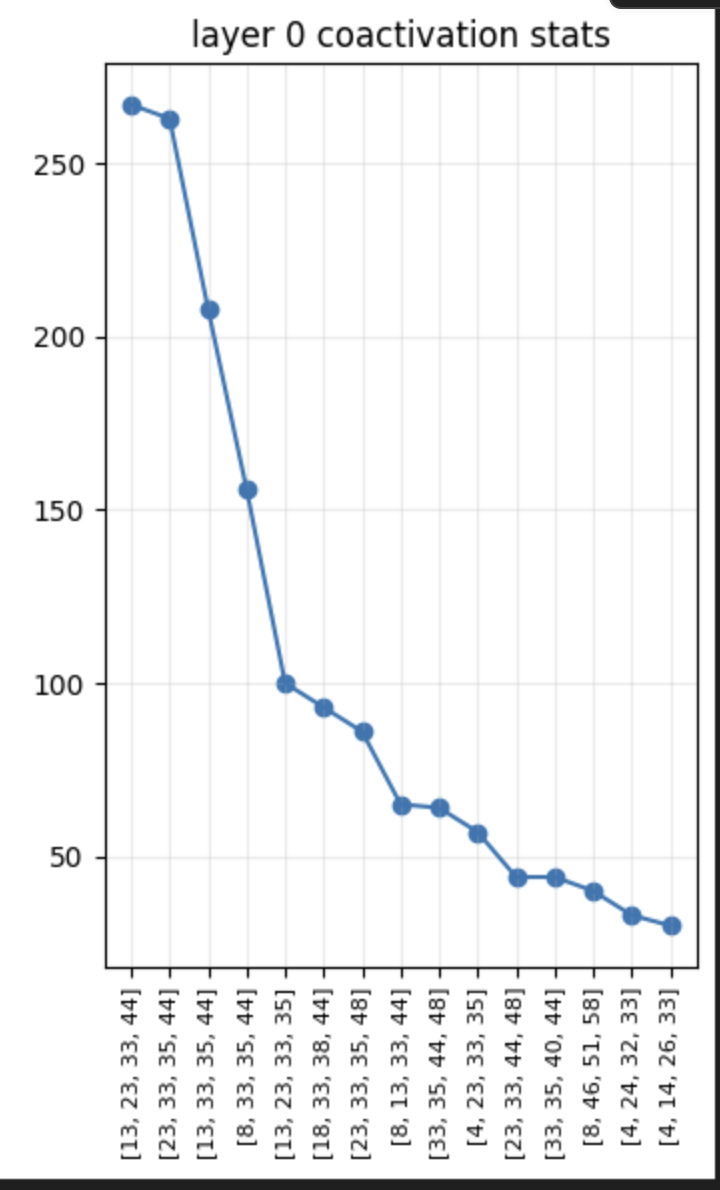